In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import matplotlib.dates as mdates
from matplotlib.patches import Ellipse, ConnectionPatch
from pathlib import Path


In [15]:

Data = pd.read_excel(Path("..") / "Dataset" / "Q_tot.xlsx")
Data=Data[Data.index>0]
Data

,Date,Q_tronto,Aquifer discharge,Q_Inf+RO+Uro_S (m3/s),Q_tot,MEF,Net available discharge (-MEF),Authorized withdrawalsi (agr+ind+other),Civil water withdrawal,Lake water demand,Agricultural water demand,Q_demand,Q_available-Q_demand,WWTP,Q_available-Q_demand +wwtp,INDICE PRE,INDICE POST,Delta Index
1,2013-01-01,10.558602,0.111806,0.172599,10.843006,5.04,5.803006,0.046061,0,0.025065,0,0.071126,5.73188,0.272362,6.004242,0.987743,1.034678,0.047517
2,2013-02-01,12.402228,0.111806,0.091501,12.605535,5.81,6.795535,0.046061,0,0.031971,0,0.078032,6.717502,0.319793,7.037295,0.988517,1.035576,0.047606
3,2013-03-01,20.725274,0.111806,0.089651,20.926731,5.81,15.116731,0.046061,0,0.027449,0,0.073511,15.04322,0.379235,15.422455,0.995137,1.020224,0.025210
4,2013-04-01,22.933217,0.111806,0,23.045023,5.04,18.005023,0.046061,0,0.034119,0.059193,0.139373,17.865649,0.335526,18.201175,0.992259,1.010894,0.018780
5,2013-05-01,15.196393,0.111806,0,15.308199,5.04,10.268199,0.046061,0,0.025456,0.057284,0.128801,10.139398,0.341316,10.480714,0.987456,1.020696,0.033662
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128,2023-08-01,11.099289,0.111806,0,11.211094,3.87,7.341094,0.046061,0,NaN,0.057284,0.103345,7.237749,0.101081,7.33883,0.985922,0.999692,0.013966
129,2023-09-01,9.336245,0.111806,0,9.448051,3.87,5.578051,0.046061,0,NaN,0.059193,0.105255,5.472796,0.148269,5.621066,0.981131,1.007711,0.027092
130,2023-10-01,9.198069,0.111806,0,9.309874,3.87,5.439874,0.046061,0,NaN,0,0.046061,5.393813,0.144023,5.537836,0.991533,1.018008,0.026702
131,2023-11-01,9.42106,0.111806,0,9.532865,5.04,4.492865,0.046061,0,NaN,0,0.046061,4.446804,0.120249,4.567053,0.989748,1.016512,0.027042


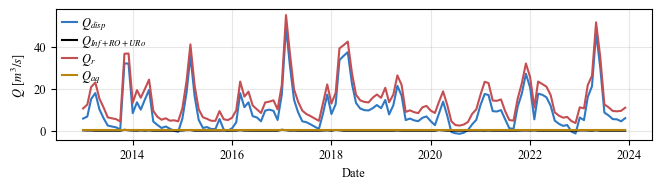

In [16]:

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

cm = 1 / 2.54
fig, ax = plt.subplots(figsize=(17*cm, 5*cm))

ax.plot(
    Data['Date'],
    Data['Q_available-Q_demand '],
    label=r'$Q_{disp}$',
    color='#2F78C4'
)

ax.plot(
    Data['Date'],
    Data['Q_Inf+RO+Uro_S (m3/s)'],
    label=r'$Q_{Inf+RO+URo}$',
    color='black'
)

ax.plot(
    Data['Date'],
    Data['Q_tronto'],
    label=r'$Q_{r}$',
    color='#C44E52'
)

ax.plot(
    Data['Date'],
    Data['Aquifer discharge'],
    label=r'$Q_{aq}$',
    color='#B8860B'
)

ax.set_xlabel('Date')
ax.set_ylabel(r'$Q$ [$m^3/s$]')

ax.legend(
    loc='upper left',
    fontsize=9,
    handlelength=1.2,
    handletextpad=0.3,
    labelspacing=0.1,
    borderaxespad=0.1,
    frameon=False
)

ax.grid(True, alpha=0.3)

fig.tight_layout()

fig.savefig(
    (Path("..") / "Results_Balance" / "Figure6.pdf"),
    format="pdf",
    bbox_inches="tight"
)

plt.show()


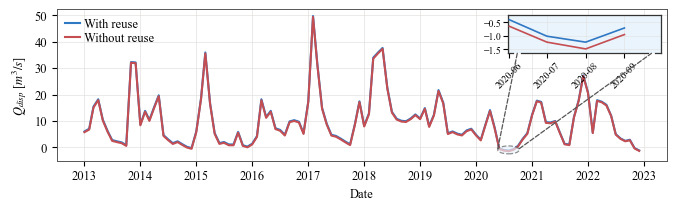

In [17]:

plt.rcParams.update({
    'font.family': 'Times New Roman',
    'font.size': 9,
    'axes.labelsize': 9,
    'axes.titlesize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'mathtext.fontset': 'stix',
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
})

cm = 1 / 2.54

BLUE = '#2F78C4'
RED = '#C44E52'
GRID_COLOR = '#E3E2DE'
ZOOM_BG = '#EAF4FC'

start_date_zoom = pd.Timestamp('2020-05-31')
end_date_zoom = pd.Timestamp('2020-09-30')

Data_plot = Data.copy()
Data_plot['Date'] = pd.to_datetime(Data_plot['Date'])

COL_BLUE = 'Q_available-Q_demand +wwtp'
COL_RED = 'Q_available-Q_demand '

mask_full = (
    (Data_plot['Date'] >= '2013-01-01') &
    (Data_plot['Date'] <= '2022-12-31')
)

Data_full = Data_plot.loc[mask_full].sort_values('Date')

mask_zoom = (
    (Data_plot['Date'] >= start_date_zoom) &
    (Data_plot['Date'] <= end_date_zoom)
)

Data_zoom = Data_plot.loc[mask_zoom].sort_values('Date')

if Data_zoom.empty:
    raise ValueError('Nessun dato disponibile nel periodo di zoom.')

fig, ax = plt.subplots(figsize=(20 * cm, 5 * cm))

ax.plot(
    Data_full['Date'],
    Data_full[COL_BLUE],
    label='With reuse',
    linewidth=1.5,
    color=BLUE,
    zorder=3
)

ax.plot(
    Data_full['Date'],
    Data_full[COL_RED],
    label='Without reuse',
    linewidth=1.5,
    color=RED,
    zorder=3
)

ax.set_xlabel('Date')
ax.set_ylabel(r'$Q_{disp}$ [$m^3/s$]')

ax.grid(
    True,
    color=GRID_COLOR,
    linewidth=0.5
)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color('#555555')
    spine.set_linewidth(0.7)

ax.legend(
    loc='upper left',
    fontsize=9,
    handlelength=1.2,
    handletextpad=0.3,
    labelspacing=0.2,
    borderaxespad=0.3,
    frameon=False
)

axins = inset_axes(
    ax,
    width='25%',
    height='25%',
    loc='upper right',
    borderpad=0.5
)

axins.plot(
    Data_zoom['Date'],
    Data_zoom[COL_BLUE],
    color=BLUE,
    linewidth=1.2,
    zorder=3
)

axins.plot(
    Data_zoom['Date'],
    Data_zoom[COL_RED],
    color=RED,
    linewidth=1.2,
    zorder=3
)

axins.set_xlim(start_date_zoom, end_date_zoom)

ymin = Data_zoom[[COL_BLUE, COL_RED]].min().min()
ymax = Data_zoom[[COL_BLUE, COL_RED]].max().max()
ypad = max((ymax - ymin) * 0.15, 0.1)

axins.set_ylim(ymin - ypad, ymax + ypad)
axins.set_facecolor(ZOOM_BG)

for spine in axins.spines.values():
    spine.set_visible(True)
    spine.set_color('#333333')
    spine.set_linewidth(0.9)

axins.spines['bottom'].set_visible(False)

gap = 0.025
x_left = 0.06
x_right = 0.94

segments = [
    (0.0, x_left - gap),
    (x_left + gap, x_right - gap),
    (x_right + gap, 1.0)
]

for x0, x1 in segments:
    axins.plot(
        [x0, x1],
        [0, 0],
        transform=axins.transAxes,
        color='#333333',
        linewidth=0.9,
        clip_on=False,
        zorder=6
    )

axins.xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)

axins.xaxis.set_major_formatter(
    mdates.DateFormatter('%Y-%m')
)

axins.tick_params(
    axis='x',
    labelsize=7,
    rotation=45,
    pad=2
)

axins.tick_params(
    axis='both',
    labelsize=7,
    direction='out',
    pad=1
)
axins.tick_params(axis='x', rotation=45)

axins.grid(
    True,
    color=GRID_COLOR,
    linewidth=0.4
)
axins.set_axisbelow(True)

x_start = mdates.date2num(start_date_zoom)
x_end = mdates.date2num(end_date_zoom)
x_center = (x_start + x_end) / 2

y_center = Data_zoom[[COL_BLUE, COL_RED]].mean().mean()

ellipse_width = (x_end - x_start) * 1.15
ellipse_height = max((ymax - ymin) * 2.0, 3.0)

ellipse = Ellipse(
    xy=(x_center, y_center),
    width=ellipse_width,
    height=ellipse_height,
    facecolor=ZOOM_BG,
    edgecolor='#555555',
    linewidth=0.9,
    linestyle='--',
    alpha=0.65,
    zorder=4
)

ax.add_patch(ellipse)

connector_left = ConnectionPatch(
    xyA=(
        x_center - ellipse_width / 2,
        y_center + ellipse_height * 0.15
    ),
    coordsA=ax.transData,
    xyB=(x_left, 0),
    coordsB=axins.transAxes,
    color='#555555',
    linewidth=0.9,
    linestyle='--',
    zorder=5
)

connector_right = ConnectionPatch(
    xyA=(
        x_center + ellipse_width / 2,
        y_center + ellipse_height * 0.15
    ),
    coordsA=ax.transData,
    xyB=(x_right, 0),
    coordsB=axins.transAxes,
    color='#555555',
    linewidth=0.9,
    linestyle='--',
    zorder=5
)

fig.add_artist(connector_left)
fig.add_artist(connector_right)

fig.savefig(
        (Path("..") / "Results_Balance" / "Figure7.pdf"),
    format='pdf',
    bbox_inches='tight',
    dpi=300
)

plt.show()
